# Exploratory Data Visualisation

Dataset: Real-World Churn (Kaggle) - https://www.kaggle.com/datasets/lasaljaywardena/real-world-churn/data

## Dataset Summary

The raw data covers **65,005 customers**, each with **90 days** of daily usage (`Day_1` to `Day_90`) across **12 services**. Each record is one customer and one service, so `main.csv` has **780,060 records** (65,005 × 12). Around **23%** of customers churned.

| Category | Services |
|---|---|
| Apps (6) | Facebook, Helakuru, TikTok, WhatsApp, YouTube, Other Apps |
| Packs (2) | Data Pack, Value-Added Services (VAS) Pack |
| Voice (4) | Incoming and outgoing calls, same network and other network |

| Split | Customers | Churned | Churn Rate |
|---|---|---|---|
| Train | 52,004 | 12,022 | 23.1% |
| Test | 13,001 | 2,978 | 22.9% |
| **Total** | **65,005** | **15,000** | **23.1%** |


## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
STAYED="#2a78d6"
CHURNED="#eb6834"
COLORS={0:STAYED,1:CHURNED}
NAMES={0:"Stayed",1:"Churned"}
INK="#0b0b0b"
MUTED="#898781"

plt.rcParams.update({"figure.dpi":110, "figure.facecolor":"white", "axes.facecolor":"white",
    "axes.edgecolor":"#c3c2b7", "axes.labelcolor":INK, "axes.titlesize":12, "axes.titleweight":"bold",
    "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "axes.axisbelow":True,
    "grid.color":"#e1e0d9", "grid.linewidth":0.6, "xtick.color":MUTED, "ytick.color":MUTED,
    "legend.frameon":False, "lines.linewidth":2})

SERVICE_LABELS={"app_facebook":"Facebook","app_helakuru":"Helakuru","app_other":"Other Apps",
    "app_tiktok":"TikTok","app_whatsapp":"WhatsApp","app_youtube":"YouTube",
    "pack_data":"Data Pack","pack_vas":"VAS Pack",
    "voice_d2d_incoming":"Voice Incoming (Same Network)","voice_d2d_outgoing":"Voice Outgoing (Same Network)",
    "voice_d2nd_outgoing":"Voice Outgoing (Other Network)","voice_nd2d_incoming":"Voice Incoming (Other Network)"}

os.makedirs("figures", exist_ok=True)
def save(fig, name):
    fig.savefig("figures/"+name+".png", dpi=150, bbox_inches="tight")

## Load Data

In [3]:
N_DAYS=90
DAY_COLS=["Day_"+str(i) for i in range(1,91)]

train_ids=pd.read_csv("data/raw/train/train_cxid.csv")
usage=pd.read_csv("data/raw/main.csv")
usage=usage.merge(train_ids,on="customer_id")
usage["service"]=usage["usage_type"].str.replace("usage_","").str.replace("_daily","")
print(usage.shape)

(624048, 94)


## Prepare Per-Service and Per-Customer Summaries

In [4]:
X=usage[DAY_COLS].to_numpy()
is_active=X>0
usage["active_days"]=is_active.sum(axis=1)
usage["last_active_day"]=np.where(is_active.any(axis=1), N_DAYS-np.argmax(is_active[:,::-1],axis=1), 0)
usage["trend_ratio"]=(X[:,60:].mean(axis=1)+1)/(X[:,:30].mean(axis=1)+1)

In [5]:
daily=usage.groupby("customer_id")[DAY_COLS].sum()
churn=train_ids.set_index("customer_id").loc[daily.index,"churn"]

cust=usage.groupby("customer_id")[["active_days","last_active_day","trend_ratio"]].mean()
cust=cust.loc[daily.index].add_prefix("avg_")
cust["churn"]=churn
cust["total"]=daily.sum(axis=1)
cust["first30"]=daily[DAY_COLS[:30]].mean(axis=1)
cust["last30"]=daily[DAY_COLS[60:]].mean(axis=1)
cust["trend_ratio"]=(cust["last30"]+1)/(cust["first30"]+1)
cust.head()

,avg_active_days,avg_last_active_day,avg_trend_ratio,churn,total,first30,last30,trend_ratio
customer_id,,,,,,,,
0000f727854b50bb95c054b39c1fe5c92e5ebcfa4bcb5dc279f56aa96a365e5a,56.250000,79.166667,1.586920,0,84594.79,748.085667,1243.927000,1.661929
0001702d0abcdbeeb23f7c434aa6858030f365caf1464aa9c383837cba2f82a6,43.916667,77.083333,0.824719,1,36706.73,447.301667,429.558667,0.960422
0001ae52a920c36edc7ab364ea58a58ca725f0ad44c02ba74ecefe08bb2b91a3,47.416667,83.916667,1.100068,1,70557.33,635.487000,976.327000,1.535502
0002511664bff302e40b19ed6872ad4390ac59901e55e2c81a9cc02b21de783a,62.916667,86.250000,1.682211,0,53188.96,447.063667,776.298667,1.734795
0003dbd80ea9a5fb7a2efabdb984c5fa75450cda717e39853758fb19531a663b,62.416667,88.083333,1.677700,0,76186.26,567.485000,1207.062667,2.125056


## 1. Class Distribution

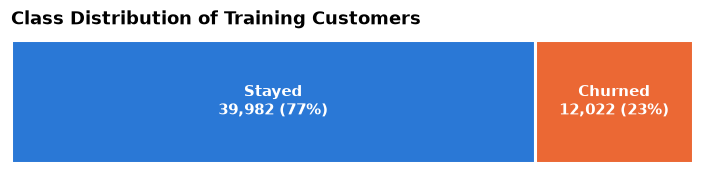

In [6]:
counts=cust["churn"].value_counts().sort_index()
share=counts/counts.sum()

fig,ax=plt.subplots(figsize=(8,1.6))
left=0
for l in [0,1]:
    ax.barh(0,share[l],left=left,color=COLORS[l],height=0.5,edgecolor="white",linewidth=2)
    ax.text(left+share[l]/2, 0, f"{NAMES[l]}\n{counts[l]:,} ({share[l]:.0%})", ha="center",va="center",color="white",fontweight="bold")
    left+=share[l]
ax.set_xlim(0,1)
ax.axis("off")
ax.set_title("Class Distribution of Training Customers",loc="left")
save(fig,"01_class_balance")
plt.show()

## 2. Total Daily Usage over Time

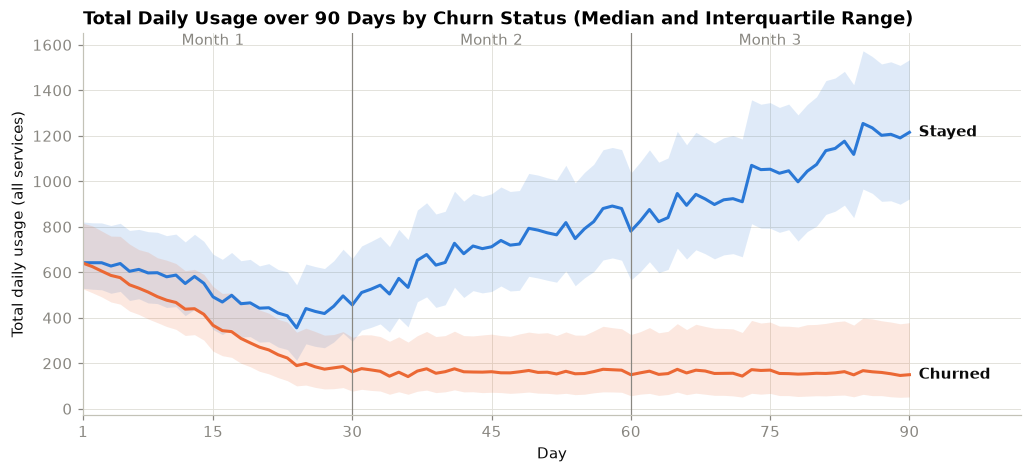

In [7]:
fig,ax=plt.subplots(figsize=(11,4.5))
days=np.arange(1,91)
for l in [0,1]:
    q25,q50,q75=daily[churn==l].quantile([0.25,0.5,0.75]).to_numpy()
    ax.fill_between(days,q25,q75,color=COLORS[l],alpha=0.15,linewidth=0)
    ax.plot(days,q50,color=COLORS[l])
    ax.text(91,q50[-1],NAMES[l],color=INK,va="center",fontweight="bold")

ax.axvline(30,color=MUTED,linewidth=0.8)
ax.axvline(60,color=MUTED,linewidth=0.8)
top=ax.get_ylim()[1]*0.97
ax.text(15,top,"Month 1",ha="center",color=MUTED)
ax.text(45,top,"Month 2",ha="center",color=MUTED)
ax.text(75,top,"Month 3",ha="center",color=MUTED)
ax.set_xlim(1,102)
ax.set_xticks([1,15,30,45,60,75,90])
ax.set_xlabel("Day")
ax.set_ylabel("Total daily usage (all services)")
ax.set_title("Total Daily Usage over 90 Days by Churn Status (Median and Interquartile Range)",loc="left")
save(fig,"02_usage_over_time")
plt.show()

## 3. Indexed Usage by Service

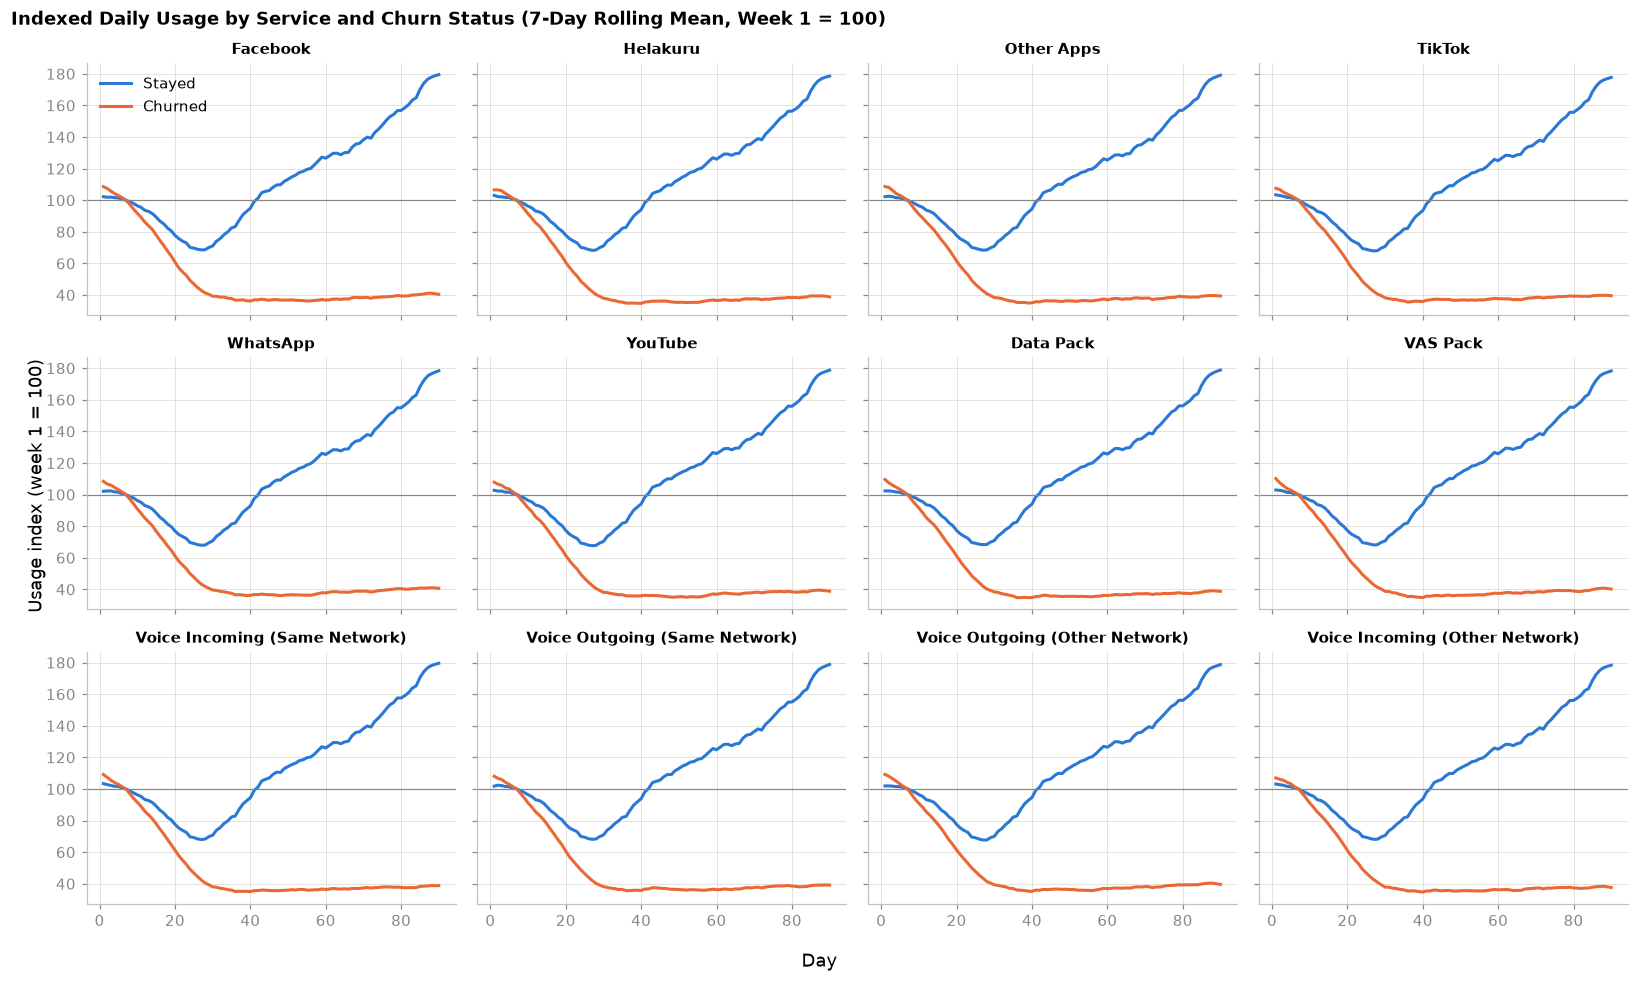

In [8]:
services=sorted(usage["service"].unique())
fig,axes=plt.subplots(3,4,figsize=(15,9),sharex=True,sharey=True)
for ax,s in zip(axes.flat,services):
    sub=usage[usage["service"]==s]
    for l in [0,1]:
        m=sub.loc[sub["churn"]==l,DAY_COLS].mean().to_numpy()
        sm=pd.Series(m).rolling(7,min_periods=1).mean()
        ax.plot(days,sm/m[:7].mean()*100,color=COLORS[l],label=NAMES[l])
    ax.axhline(100,color=MUTED,linewidth=0.8)
    ax.set_title(SERVICE_LABELS[s],fontsize=10)
axes[0,0].legend(loc="upper left")
fig.supxlabel("Day")
fig.supylabel("Usage index (week 1 = 100)")
fig.suptitle("Indexed Daily Usage by Service and Churn Status (7-Day Rolling Mean, Week 1 = 100)",x=0.01,ha="left",fontweight="bold")
plt.tight_layout()
save(fig,"03_services_indexed")
plt.show()

## 4. Service Activity and Last Active Day

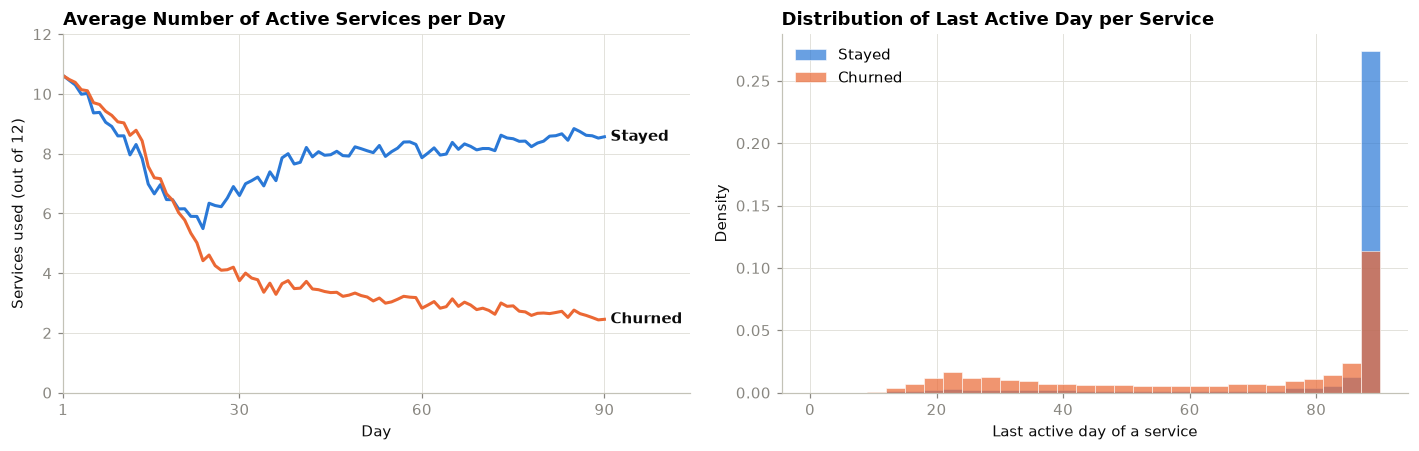

share of services not used on the last day:
churn
Stayed     0.286
Churned    0.795
Name: last_active_day, dtype: float64


In [9]:
sa=pd.DataFrame(is_active,index=usage["customer_id"]).groupby(level=0).sum()
sa=sa.loc[daily.index]

fig,axes=plt.subplots(1,2,figsize=(13,4.2))
for l in [0,1]:
    c=sa[churn==l].mean().to_numpy()
    axes[0].plot(days,c,color=COLORS[l])
    axes[0].text(91,c[-1],NAMES[l],color=INK,va="center",fontweight="bold")
axes[0].set_ylim(0,12)
axes[0].set_xlim(1,104)
axes[0].set_xticks([1,30,60,90])
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Services used (out of 12)")
axes[0].set_title("Average Number of Active Services per Day",loc="left")

bins=np.arange(0,93,3)
for l in [0,1]:
    axes[1].hist(usage.loc[usage["churn"]==l,"last_active_day"],bins=bins,color=COLORS[l],alpha=0.7,label=NAMES[l],edgecolor="white",linewidth=0.5,density=True)
axes[1].set_xlabel("Last active day of a service")
axes[1].set_ylabel("Density")
axes[1].set_title("Distribution of Last Active Day per Service",loc="left")
axes[1].legend(loc="upper left")
plt.tight_layout()
save(fig,"04_services_switched_off")
plt.show()

stopped=usage.groupby("churn")["last_active_day"].apply(lambda s:(s<90).mean())
print("share of services not used on the last day:")
print(stopped.rename(NAMES).round(3))

## 5. Usage Mix by Service

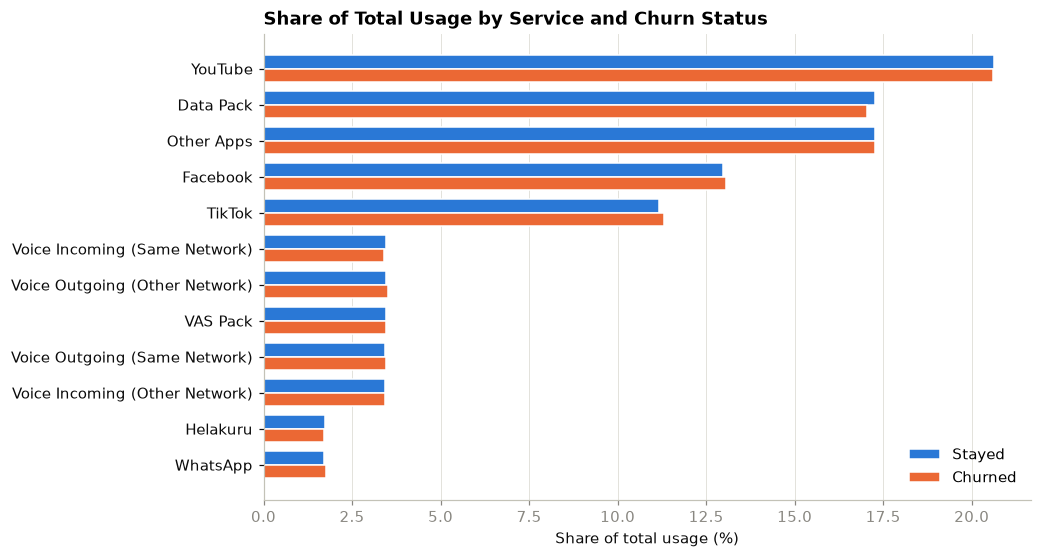

churn,0,1
service,,
app_whatsapp,1.7,1.8
app_helakuru,1.7,1.7
voice_nd2d_incoming,3.4,3.4
voice_d2d_outgoing,3.4,3.4
pack_vas,3.4,3.5
voice_d2nd_outgoing,3.4,3.5
voice_d2d_incoming,3.5,3.4
app_tiktok,11.2,11.3
app_facebook,13.0,13.1


In [10]:
mix=usage.groupby(["churn","service"])[DAY_COLS].sum().sum(axis=1).unstack(0)
mix=mix/mix.sum()*100
mix=mix.sort_values(0)

fig,ax=plt.subplots(figsize=(9,5.5))
y=np.arange(len(mix))
ax.barh(y+0.19,mix[0],height=0.38,color=STAYED,label=NAMES[0],edgecolor="white",linewidth=1)
ax.barh(y-0.19,mix[1],height=0.38,color=CHURNED,label=NAMES[1],edgecolor="white",linewidth=1)
ax.set_yticks(y,[SERVICE_LABELS[s] for s in mix.index])
ax.tick_params(axis="y",colors=INK)
ax.grid(axis="y",visible=False)
ax.set_xlabel("Share of total usage (%)")
ax.set_title("Share of Total Usage by Service and Churn Status",loc="left")
ax.legend(loc="lower right")
save(fig,"05_usage_mix")
plt.show()
mix.round(1)

## 6. Month 1 vs Month 3 Usage

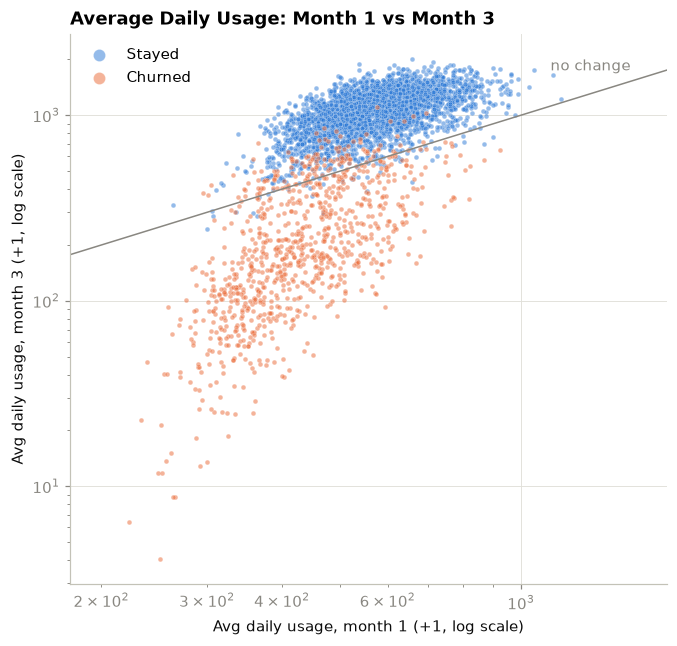

In [11]:
sample=cust.sample(4000,random_state=42)
fig,ax=plt.subplots(figsize=(7,6.5))
for l in [0,1]:
    s=sample[sample["churn"]==l]
    ax.scatter(s["first30"]+1,s["last30"]+1,s=10,color=COLORS[l],alpha=0.5,label=NAMES[l],edgecolors="white",linewidths=0.3)
ax.set_xscale("log")
ax.set_yscale("log")
lims=[sample["first30"].min()*0.8, sample["first30"].max()*1.5]
ax.set_xlim(lims)
ax.plot(lims,lims,color=MUTED,linewidth=1)
ax.text(lims[1]/1.15,lims[1]/1.05,"no change",color=MUTED,ha="right",va="bottom")
ax.set_xlabel("Avg daily usage, month 1 (+1, log scale)")
ax.set_ylabel("Avg daily usage, month 3 (+1, log scale)")
ax.set_title("Average Daily Usage: Month 1 vs Month 3",loc="left")
ax.legend(loc="upper left",markerscale=2.5)
save(fig,"06_month1_vs_month3")
plt.show()

## 7. Individual Customer Timelines

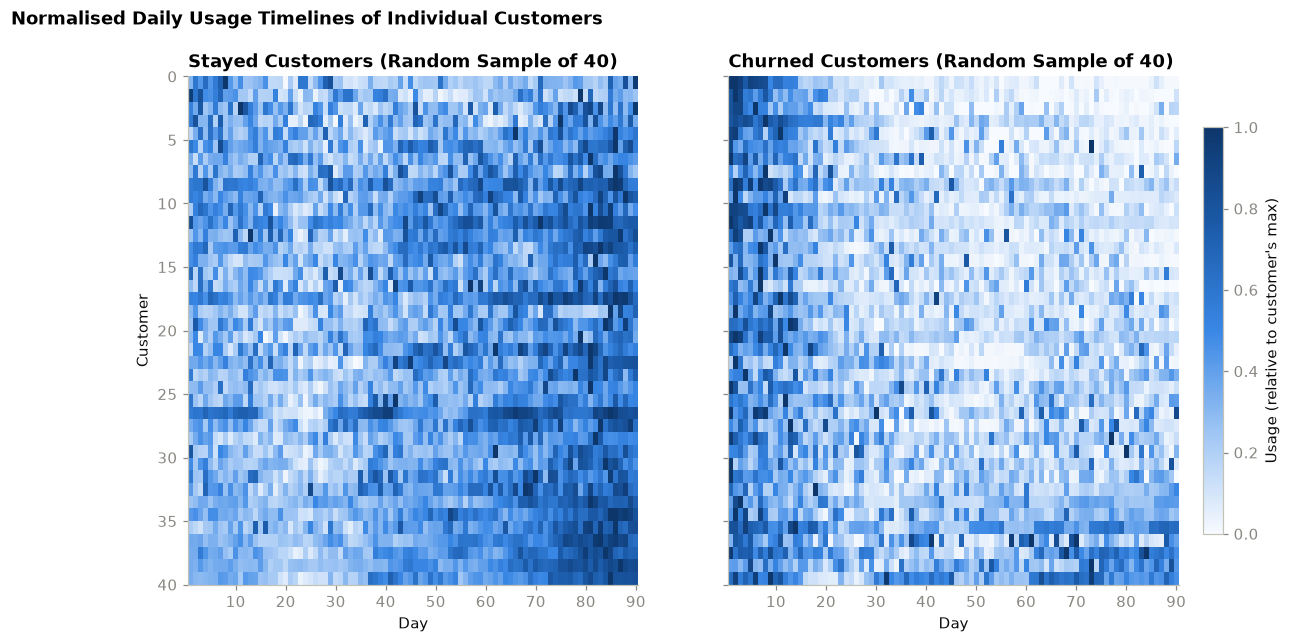

In [12]:
blues=LinearSegmentedColormap.from_list("b",["#f7fafe","#9ec5f4","#3987e5","#1c5cab","#0d366b"])
fig,axes=plt.subplots(1,2,figsize=(14,6),sharey=True)
for ax,l in zip(axes,[0,1]):
    ids=cust[cust["churn"]==l].sample(40,random_state=1).index
    r=daily.loc[ids].to_numpy()
    r=r/(r.max(axis=1,keepdims=True)+1e-9)
    o=np.argsort(cust.loc[ids,"trend_ratio"].to_numpy())
    im=ax.imshow(r[o],aspect="auto",cmap=blues,interpolation="nearest",extent=[0.5,90.5,40,0])
    ax.set_title(f"{NAMES[l]} Customers (Random Sample of 40)",loc="left")
    ax.set_xlabel("Day")
    ax.grid(False)
axes[0].set_ylabel("Customer")
cb=fig.colorbar(im,ax=axes,shrink=0.8,pad=0.02)
cb.set_label("Usage (relative to customer's max)")
fig.suptitle("Normalised Daily Usage Timelines of Individual Customers",x=0.01,ha="left",fontweight="bold")
save(fig,"07_customer_timelines")
plt.show()

## 8. Distribution of Key Features

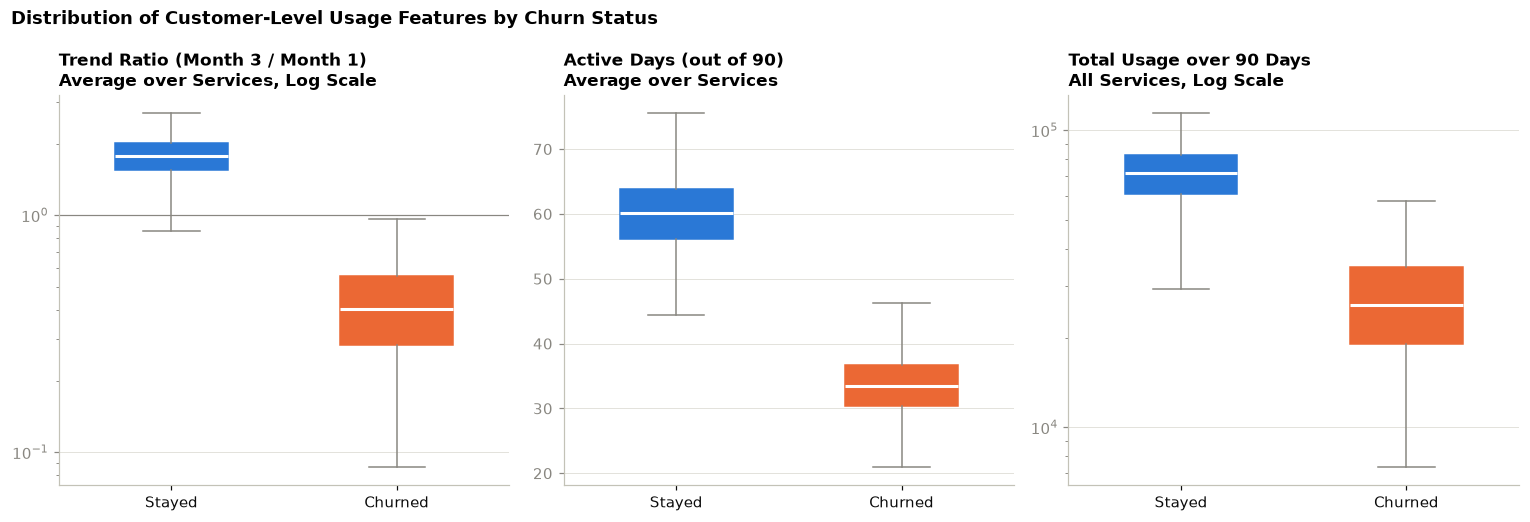

In [13]:
cols=[("avg_trend_ratio","Trend Ratio (Month 3 / Month 1)\nAverage over Services, Log Scale",True),
      ("avg_active_days","Active Days (out of 90)\nAverage over Services",False),
      ("total","Total Usage over 90 Days\nAll Services, Log Scale",True)]
fig,axes=plt.subplots(1,3,figsize=(14,4.8))
for ax,(c,t,lg) in zip(axes,cols):
    bp=ax.boxplot([cust.loc[cust["churn"]==l,c] for l in [0,1]],widths=0.5,patch_artist=True,showfliers=False,medianprops=dict(color="white",linewidth=2))
    for b,l in zip(bp["boxes"],[0,1]):
        b.set_facecolor(COLORS[l]); b.set_edgecolor(COLORS[l])
    for ln in bp["whiskers"]+bp["caps"]:
        ln.set_color(MUTED)
    ax.set_xticks([1,2],[NAMES[0],NAMES[1]])
    ax.tick_params(axis="x",colors=INK)
    ax.grid(axis="x",visible=False)
    if lg: ax.set_yscale("log")
    ax.set_title(t,loc="left",fontsize=11)
axes[0].axhline(1,color=MUTED,linewidth=0.8)
fig.suptitle("Distribution of Customer-Level Usage Features by Churn Status",x=0.01,ha="left",fontweight="bold")
plt.tight_layout()
save(fig,"08_feature_boxplots")
plt.show()

## 9. Single-Feature ROC-AUC

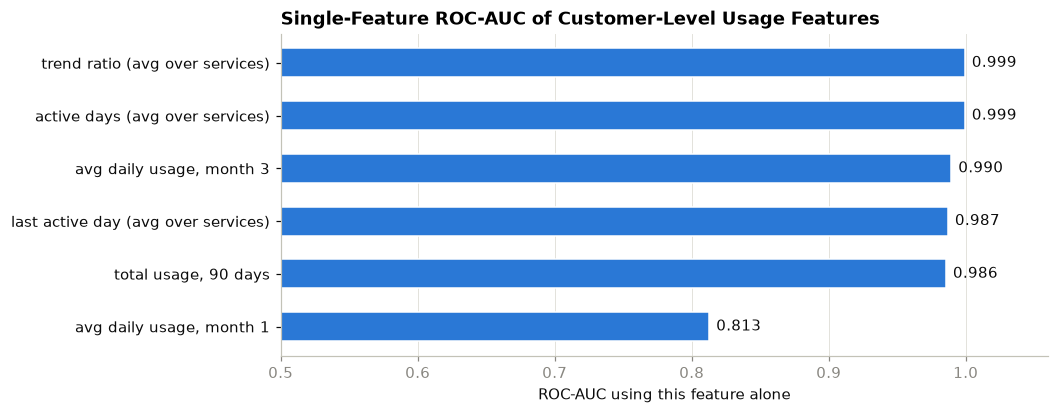

In [14]:
from sklearn.metrics import roc_auc_score

feats={"avg_trend_ratio":"trend ratio (avg over services)",
       "avg_active_days":"active days (avg over services)",
       "avg_last_active_day":"last active day (avg over services)",
       "last30":"avg daily usage, month 3",
       "total":"total usage, 90 days",
       "first30":"avg daily usage, month 1"}
res=[]
for c in feats:
    a=roc_auc_score(cust["churn"],cust[c])
    res.append([feats[c],max(a,1-a)])
auc_df=pd.DataFrame(res,columns=["feature","auc"]).sort_values("auc")

fig,ax=plt.subplots(figsize=(9,3.8))
ax.barh(auc_df["feature"],auc_df["auc"]-0.5,left=0.5,color=STAYED,height=0.55,edgecolor="white")
for i,v in enumerate(auc_df["auc"]):
    ax.text(v+0.005,i,f"{v:.3f}",va="center",color=INK)
ax.set_xlim(0.5,1.06)
ax.tick_params(axis="y",colors=INK)
ax.grid(axis="y",visible=False)
ax.set_xlabel("ROC-AUC using this feature alone")
ax.set_title("Single-Feature ROC-AUC of Customer-Level Usage Features",loc="left")
save(fig,"09_single_feature_auc")
plt.show()

## 10. Trend Ratio ROC-AUC by Service

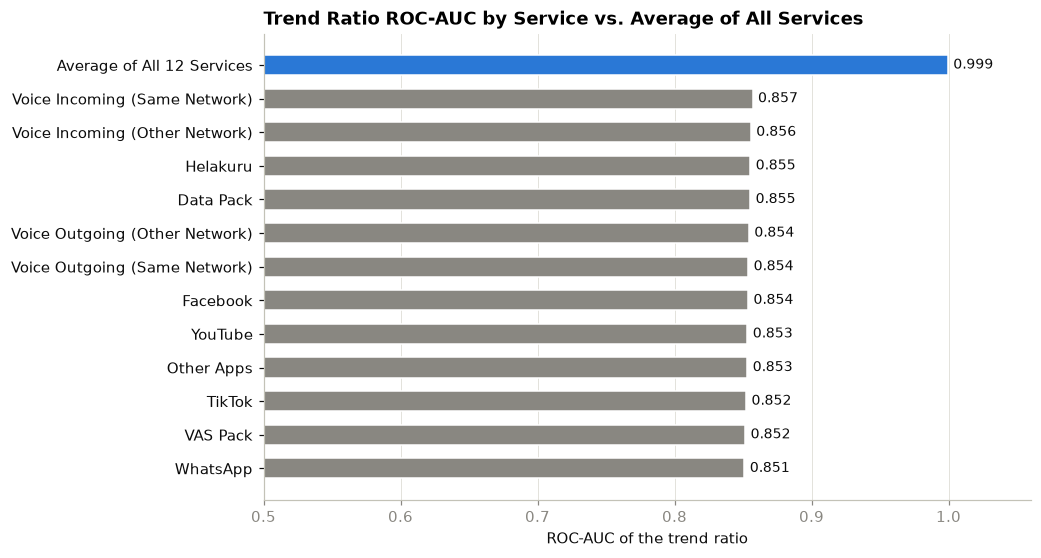

In [15]:
sauc={}
for s,g in usage.groupby("service"):
    a=roc_auc_score(g["churn"],g["trend_ratio"])
    sauc[s]=max(a,1-a)
sauc=pd.Series(sauc).sort_values()
a=roc_auc_score(cust["churn"],cust["avg_trend_ratio"])
comb=max(a,1-a)

fig,ax=plt.subplots(figsize=(9,5.5))
vals=list(sauc.values)+[comb]
ax.barh([SERVICE_LABELS[s] for s in sauc.index]+["Average of All 12 Services"],np.array(vals)-0.5,left=0.5,color=[MUTED]*len(sauc)+[STAYED],height=0.6,edgecolor="white")
for i,v in enumerate(vals):
    ax.text(v+0.004,i,f"{v:.3f}",va="center",color=INK,fontsize=9)
ax.set_xlim(0.5,1.06)
ax.tick_params(axis="y",colors=INK)
ax.grid(axis="y",visible=False)
ax.set_xlabel("ROC-AUC of the trend ratio")
ax.set_title("Trend Ratio ROC-AUC by Service vs. Average of All Services",loc="left")
save(fig,"10_service_vs_combined")
plt.show()

## 11. Correlation of Trend Ratios between Services

In [16]:
tw=usage.pivot(index="customer_id",columns="service",values="trend_ratio")
corr=np.log(tw).corr()
print(f"average correlation between services (log trend ratio): {corr.where(~np.eye(len(corr),dtype=bool)).stack().mean():.2f}")

average correlation between services (log trend ratio): 0.30
